In [1]:
import torch
import pandas as pd
import pickle
from tqdm import tqdm

import os
import sys
base_dir = os.getcwd()
sys.path.append(os.path.dirname(base_dir))
from nesy_gnn.models import FuzzyGAT, FuzzyNN
from nesy_gnn.train_model import train_epoch, evaluate, build_pyg_data

/home/xyu/.conda/envs/firegnn/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [48]:
def load_graph(filepath):
    with open(filepath, 'rb') as f:
        G = pickle.load(f)
    print(f"Load graph with {G.number_of_nodes()} nodes and {G.number_of_edges()} edges")
    return G

In [49]:
G = load_graph("../nesy_gnn/results/updated/AD_KG/ANMerge/4/patient_graph.gpickle")
data_all      = build_pyg_data(G, use_direct_rules=False)
data_direct   = build_pyg_data(G, use_direct_rules=True)

Load graph with 691 nodes and 1406 edges
Computing topological features...
Computing topological features...


In [50]:
data_direct

Data(x=[691, 4444], edge_index=[2, 2812], edge_attr=[2812], y=[691], kg_scores=[691, 185], topo_features=[691, 5], topo_scaler_mean=[5], topo_scaler_scale=[5])

In [51]:
data_all

Data(x=[691, 4444], edge_index=[2, 2812], edge_attr=[2812], y=[691], kg_scores=[691, 741], topo_features=[691, 5], topo_scaler_mean=[5], topo_scaler_scale=[5])

In [52]:
data_direct.topo_features.size(1) + data_direct.kg_scores.size(1)

190

In [55]:
model2 = FuzzyNN(in_channels=data_direct.x.size(1), 
                            hidden_channels=64, 
                            out_channels=2, 
                            num_rules=data_direct.topo_features.size(1) + data_direct.kg_scores.size(1),
                            num_layers=2,
                            )
optimizer2 = torch.optim.AdamW(model2.parameters(), lr=1e-4, weight_decay=1e-5)

In [54]:
model = FuzzyGAT(in_channels=data_direct.x.size(1), 
                            hidden_channels=64, 
                            out_channels=2, 
                            num_rules=190,
                            num_layers=2,
                            heads=4,)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-5)

In [56]:
import numpy as np
from sklearn.model_selection import train_test_split


train_idx, test_idx = train_test_split(np.arange(data_direct.x.size(0)), 
                                       test_size=0.2, 
                                       stratify = data_direct.y, 
                                       random_state=42)
train_mask = torch.zeros(data_direct.x.size(0), dtype=torch.bool)
test_mask = torch.zeros(data_direct.x.size(0), dtype=torch.bool)
train_mask[train_idx]=True
test_mask[test_idx]=True

for _ in tqdm(range(10), desc="Training"):
    loss = train_epoch(model=model2,
                       data=data_direct,
                       train_mask=train_mask,
                       optimizer=optimizer2,
                       use_kg=True,
                       use_topo=True)

Training:   0%|          | 0/10 [00:00<?, ?it/s]

Training: 100%|██████████| 10/10 [00:00<00:00, 25.62it/s]


In [57]:
fuzzy_params = {
                "theta": getattr(model.fuzzy_layer, "theta", None),
                "alpha": getattr(model.fuzzy_layer, "alpha", None)
            }
cls_weight = model.classifier.weight # [out_dim, hidden_dim]
activation_weight = model.rule_proj.weight # [hidden_dim, num_rules]
activation_weight.size()

torch.Size([64, 190])

In [59]:
result = model2(
            x=data_direct.x,
            edge_index=data_direct.edge_index,
            edge_attr=data_direct.edge_attr,
            rule_features=torch.cat([data_direct.topo_features, data_direct.kg_scores], dim=1)
        )
result['rules'].size()

torch.Size([691, 190])

In [9]:
result = model(
            data_direct.x,
            data_direct.edge_index,
            data_direct.edge_attr,
            torch.cat([data_direct.topo_features, data_direct.kg_scores], dim=1)
        )
logits = result["logits"]
r = result["rules"]
e = result["rule_embedding"]
g = result["gate"]

num_classes = logits.size(1)
num_classes

2

In [26]:
g.abs().mean(dim=1).shape

torch.Size([691])

In [22]:
result.keys()

dict_keys(['logits', 'rules', 'rule_embedding', 'gate', 'gnn_embedding', 'fused_embedding'])

In [60]:
def get_rule_params(model, data, rule_feature):

    model.eval()
    model.zero_grad(set_to_none=True)

    result = model(
        x=data.x,
        edge_index=data.edge_index,
        edge_attr=data.edge_attr,
        rule_features=rule_feature
    )

    logits = result["logits"]
    r = result["rules"]
    g = result["gate"]

    # IMPORTANT:
    # Do NOT use torch.no_grad() here.
    # We need the autograd graph.
    assert r.requires_grad

    # ---------------------------------------------------------
    # Rule activation statistics
    # ---------------------------------------------------------
    mean_activation = r.detach().mean(dim=0)
    std_activation = r.detach().std(dim=0)

    activation_rate = (
        (r.detach() > 0.5)
        .float()
        .mean(dim=0)
    )

    # ---------------------------------------------------------
    # Gradient × activation: class 0
    # ---------------------------------------------------------
    score_0 = logits[:, 0].sum()

    grad_0 = torch.autograd.grad(
        score_0,
        r,
        retain_graph=True
    )[0]

    importance_class_0 = (
        r.detach() * grad_0.detach()
    ).abs().mean(dim=0)

    # ---------------------------------------------------------
    # Gradient × activation: class 1
    # ---------------------------------------------------------
    score_1 = logits[:, 1].sum()

    grad_1 = torch.autograd.grad(
        score_1,
        r,
        retain_graph=True
    )[0]

    importance_class_1 = (
        r.detach() * grad_1.detach()
    ).abs().mean(dim=0)

    # ---------------------------------------------------------
    # Gradient × activation: predicted class
    # ---------------------------------------------------------
    predicted_class = logits.detach().argmax(dim=1)

    predicted_score = logits[
        torch.arange(logits.size(0), device=logits.device),
        predicted_class
    ].sum()

    grad_pred = torch.autograd.grad(
        predicted_score,
        r
    )[0]

    importance_prediction = (
        r.detach() * grad_pred.detach()
    ).abs().mean(dim=0)

    # ---------------------------------------------------------
    # Alpha / theta
    # ---------------------------------------------------------
    alpha = model.fuzzy_layer.alpha.detach().cpu()
    theta = model.fuzzy_layer.theta.detach().cpu()

    # ---------------------------------------------------------
    # DataFrame
    # ---------------------------------------------------------
    rule_df = pd.DataFrame({
        "rule": range(len(alpha)),
        "alpha": alpha.numpy(),
        "theta": theta.numpy(),
        "mean_activation": mean_activation.cpu().numpy(),
        "std_activation": std_activation.cpu().numpy(),
        "activation_rate": activation_rate.cpu().numpy(),
        "grad_rule_importance_prediction":
            importance_prediction.cpu().numpy(),
        "importance_class_0":
            importance_class_0.cpu().numpy(),
        "importance_class_1":
            importance_class_1.cpu().numpy(),
    })

    return rule_df, result

In [14]:
num_rules = data_direct.topo_features.size(1) + data_direct.kg_scores.size(1)
rule_feature = torch.cat([data_direct.topo_features, data_direct.kg_scores], dim=1)
rule_feature.size()

torch.Size([691, 190])

In [15]:
rule_feature = torch.cat([data_direct.topo_features, data_direct.kg_scores], dim=1)

df_rule_params2 = get_rule_params(model=model2, 
                                  data=data_direct, 
                                  rule_feature=rule_feature)

Number of rules: 190
rule features size: torch.Size([691, 190])


In [8]:
df_rule_params = get_rule_params(model=model, data=data_direct, rule_feature)
df_rule_params

,rule,alpha,theta,mean_activation,std_activation,activation_rate,grad_rule_importance_prediction,importance_class_0,importance_class_1
0,0,0.999048,-0.000924,0.487095,0.161220,0.280753,0.006196,0.003002,0.007017
1,1,0.999103,-0.000765,0.483925,0.192823,0.356006,0.004480,0.001384,0.005462
2,2,1.000912,0.000929,0.478777,0.136946,0.178003,0.005352,0.002387,0.005611
3,3,1.000951,0.000913,0.486643,0.161467,0.280753,0.005711,0.015810,0.003506
4,4,0.999124,0.000870,0.526933,0.098360,0.888567,0.012156,0.004443,0.013437
...,...,...,...,...,...,...,...,...,...
185,185,1.000413,-0.000911,0.500914,0.226886,0.493488,0.003392,0.010222,0.002274
186,186,0.999642,0.000903,0.502229,0.213011,0.499276,0.004342,0.001596,0.004871
187,187,0.999106,-0.000205,0.500536,0.225529,0.493488,0.000786,0.001902,0.000705
188,188,0.999734,0.000907,0.501374,0.213525,0.497829,0.008901,0.017907,0.007369


### Permutation Importance

In [61]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
)
import torch.nn.functional as F

def test(true, logits):
    pred = logits.argmax(dim=1)
    prob = torch.exp(logits)[:,1]

    metrics = {}
    acc = accuracy_score(true, pred)
    metrics["f1"] = f1_score(true, pred, zero_division=0)
    metrics["f1_macro"] = f1_score(
        true,
        pred,
        average="macro",
        zero_division=0,
    )
    metrics["f1_weighted"] = f1_score(
        true,
        pred,
        average="weighted",
        zero_division=0,
    )

    metrics["auroc"] = roc_auc_score(true, prob)
    
    metrics["auprc"] = average_precision_score(true, prob)
    
    return metrics

@torch.no_grad()
def permutation_importance(model, data, rule_features, labels, metric_name):
    model.eval()

    baseline_out = model(x=data.x, 
        edge_index=data.edge_index, 
        edge_attr=data.edge_attr, 
        rule_features = rule_features)
    baseline_logits = F.log_softmax(baseline_out['logits'], dim=1)
    
    baseline_score = test(labels, baseline_logits)[metric_name]

    importance = []

    for j in range(rule_features.size(1)):
        X_perm = rule_features.clone()

        # Shuffle feature j across nodes
        perm = torch.randperm(X_perm.size(0), device=X_perm.device)
        X_perm[:, j] = X_perm[perm, j]

        out_perm = model(x=data.x, 
                                edge_index=data.edge_index, 
                                edge_attr=data.edge_attr, 
                                rule_features = X_perm)
        logits_perm = F.log_softmax(out_perm['logits'], dim=1)
        
        perm_score = test(labels, logits_perm)[metric_name]

        # Larger drop = more important
        importance.append(baseline_score - perm_score)

    return torch.tensor(importance)

In [62]:
rule_feature = torch.cat(
            [data_direct.topo_features, data_direct.kg_scores],
            dim=1
        )
importance = permutation_importance(model=model,
                                    data=data_direct,
                                    rule_features=rule_feature,
                                    metric_name='auroc',
                                    labels=data_direct.y)

In [63]:
importance.size()

torch.Size([190])

### Intergrated-Gradient based Importance

In [64]:
import torch
from captum.attr import IntegratedGradients

# 1. Create a minimal Wrapper to hide the GNN structure from Captum
class RuleFeatureWrapper(torch.nn.Module):
    def __init__(self, model, x, edge_index, edge_attr=None):
        super().__init__()
        self.model = model
        self.x = x
        self.edge_index = edge_index
        self.edge_attr = edge_attr
        
    def forward(self, rule_features):
        # We only pass rule_features from Captum.
        # The graph structure (x, edge_index) stays static.
        out = self.model(
            x=self.x, 
            edge_index=self.edge_index, 
            edge_attr=self.edge_attr, 
            rule_features=rule_features
        )
        # Captum needs a raw tensor output, so we return the logits
        return out["logits"]

def captum_explain(model, data,rule_feature, targets:torch.Tensor):
    model.eval()
    wrapper = RuleFeatureWrapper(
        model=model, 
        x=data.x, 
        edge_index=data.edge_index, 
        edge_attr=getattr(data, 'edge_attr', None)
    )

    # 3. Initialize Integrated Gradients
    ig = IntegratedGradients(wrapper)

    num_nodes = rule_feature.size(0)

    attributions, delta = ig.attribute(
        inputs=rule_feature,
        target=targets,
        internal_batch_size=num_nodes,  
        n_steps=50, # Optional: number of interpolation steps
        return_convergence_delta=True
    )

    print("Attributions shape:", attributions.shape) # Should be [N, num_rules]
    feature_importance = attributions.abs().mean(dim=0)

    return feature_importance, attributions
    

In [65]:
feature_importance, attributions = captum_explain(model, data_direct, rule_feature, data_direct.y)

feature_importance.size()

Attributions shape: torch.Size([691, 190])


torch.Size([190])

In [28]:
pd.DataFrame(attributions)

,0,1,2,3,4,5,6,7,8,9,...,180,181,182,183,184,185,186,187,188,189
0,0.000020,0.000362,0.000218,0.000060,0.000349,0.000439,7.885745e-07,0.000670,0.001196,-0.000758,...,-0.000129,0.003572,-0.002504,0.002268,-0.002874,0.000490,0.004244,-0.000010,-0.000270,0.001248
1,0.000019,0.000451,-0.000112,0.000054,0.000284,0.001233,1.306042e-04,0.000772,0.001216,-0.000814,...,0.000086,0.002214,-0.001703,0.001509,-0.003679,0.000014,0.002065,0.000065,-0.000699,0.001216
2,0.000112,0.001478,-0.000027,0.000102,0.000004,0.002376,4.937003e-04,0.001839,0.000835,-0.000031,...,0.003505,-0.002192,-0.000003,0.004622,-0.002931,-0.003909,0.000612,-0.008803,-0.002452,-0.003241
3,0.000100,-0.000610,-0.000007,0.000093,-0.000043,0.001097,1.054507e-04,0.000185,0.000779,0.000056,...,0.001521,-0.002436,0.000181,0.002146,-0.002898,-0.004832,0.003109,-0.006593,-0.004540,-0.001768
4,0.000099,0.004839,-0.000863,0.000099,0.000077,0.001721,2.422064e-05,0.001045,0.000433,0.000436,...,0.002467,-0.001220,0.000231,0.003509,-0.002873,-0.003718,0.001999,-0.011666,-0.001401,-0.003366
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
686,0.002621,-0.007197,0.000396,0.003200,-0.000264,-0.000237,-1.838170e-03,-0.001420,-0.005749,0.000203,...,0.001536,-0.002674,0.006329,-0.000177,0.004335,0.001467,0.000163,-0.000430,-0.000008,-0.000482
687,-0.001222,-0.005657,0.000752,-0.001593,-0.000217,-0.001729,4.352468e-03,-0.003571,-0.002975,-0.000282,...,0.002338,-0.001713,0.004726,0.000426,0.001241,0.000156,-0.001145,-0.000553,0.000157,-0.002019
688,0.000361,-0.001132,0.000174,0.000797,0.000201,0.001120,1.929452e-04,0.002303,0.000629,-0.000487,...,0.000535,0.002008,-0.002811,0.001732,-0.001619,-0.000414,-0.000834,0.000146,0.000288,0.002706
689,-0.001606,0.001164,-0.000444,-0.004252,0.000303,0.000277,-2.299219e-05,0.001445,0.001062,-0.000748,...,-0.000107,0.001005,-0.001327,0.001739,-0.001216,0.000294,0.005138,-0.000013,-0.000804,0.001765


## Summarize Rule Importance and Per Sample's Prediction Importance

In [40]:
import torch.nn.functional as F

def explain(model, data, rule_feature,rule_names, patients, metric_name:str):

    # get rule importances
    df, results = get_rule_params(model=model, 
                                            data=data,
                                            rule_feature=rule_feature)
    true_labels = data.y.clone().detach()
    pred_labels = F.log_softmax(results['logits'], dim=1).argmax(dim=1)

    perm_true_importance = permutation_importance(model=model,
                                             data=data,
                                             rule_features=rule_feature,
                                             labels=true_labels,
                                             metric_name=metric_name)
    perm_pred_importance = permutation_importance(model=model,
                                             data=data,
                                             rule_features=rule_feature,
                                             labels=pred_labels,
                                             metric_name=metric_name)
    ig_true_importance, true_attribution = captum_explain(model=model,
                                        data=data,
                                        rule_feature=rule_feature,
                                        targets=true_labels)
    ig_pred_importance, pred_attribution = captum_explain(model=model,
                                            data=data,
                                            rule_feature=rule_feature,
                                            targets=pred_labels)
    df['Permutation_importance(true_label)'] = perm_true_importance
    df['Permutation_importance(pred_label)'] = perm_pred_importance
    df['Integrated_Gradient_importance(true_label)'] = ig_true_importance
    df['Integrated_Gradient_importance(pred_label)'] = ig_pred_importance
    df['rule_name'] = rule_names
    df.set_index('rule_name', inplace=True)

    # create a sample df
    df_samples = pd.DataFrame(pred_attribution)
    df_samples.columns = rule_names
    g_avg = results['gate'].abs().mean(dim=1)
    df_samples['gate'] = g_avg.detach().numpy()
    df_samples['sample_id'] = patients
    df_samples['Label'] = true_labels
    df_samples['Prediction'] = pred_labels
    df_samples.set_index('sample_id', inplace=True)

    return df, df_samples

In [30]:
import json

meta_path = "../nesy_gnn/results/updated/AD_KG/ANMerge/4/graph_meta.json"
with open(meta_path, 'rb') as f:
    meta = json.load(f)

all_rules = meta['rule_names']
direct_rules = meta['direct_rule_names']
topo_features = ['degrees', 'clustering', 'eigenvector_centrality', 'degree_centrality', 'avg_edge_weight']

In [34]:
meta.keys()

dict_keys(['nodes', 'edges', 'edge_homophily', 'kg_genes', 'rule_names', 'direct_rule_names', 'patients', 'labels', 'n_kg_genes', 'n_rules', 'n_direct_rules'])

In [41]:
rule_feature = torch.cat(
    [data_direct.topo_features, data_direct.kg_scores],
    dim=1)
rule_name = topo_features+direct_rules

df_rules, df_samples = explain(model=model,
                               data=data_direct,
                               rule_feature=rule_feature,
                               rule_names=rule_name,
                               patients=meta['patients'],
                               metric_name='auroc')

Attributions shape: torch.Size([691, 190])
Attributions shape: torch.Size([691, 190])


In [42]:
df_rules

,rule,alpha,theta,mean_activation,std_activation,activation_rate,grad_rule_importance_prediction,importance_class_0,importance_class_1,Permutation_importance(true_label),Permutation_importance(pred_label),Integrated_Gradient_importance(true_label),Integrated_Gradient_importance(pred_label)
rule_name,,,,,,,,,,,,,
degrees,0,0.999377,-0.000508,0.486994,0.161264,0.280753,0.005132,0.006785,0.004662,-0.000318,0.0,0.001368,0.001250
clustering,1,1.000928,0.000845,0.483525,0.193104,0.356006,0.005453,0.003274,0.005864,-0.000064,0.0,0.001723,0.001885
eigenvector_centrality,2,1.000845,0.000862,0.478795,0.136938,0.178003,0.002352,0.000798,0.002447,-0.000055,0.0,0.000404,0.000480
degree_centrality,3,0.999815,0.000808,0.486691,0.161336,0.280753,0.007003,0.006470,0.006989,-0.000073,0.0,0.001697,0.001723
avg_edge_weight,4,1.000178,-0.000609,0.527331,0.098439,0.891462,0.003779,0.001414,0.004039,-0.000118,0.0,0.000338,0.000391
...,...,...,...,...,...,...,...,...,...,...,...,...,...
direct_PIN1_CTL,185,0.999999,0.000823,0.500569,0.226806,0.493488,0.002070,0.005536,0.001751,0.000045,0.0,0.001327,0.000803
chain_PTGS2_PTGS2_AD,186,0.999606,0.000821,0.502246,0.213006,0.499276,0.006910,0.003597,0.007955,-0.000055,0.0,0.002208,0.002438
chain_CST3_APP_CTL,187,0.999844,0.000869,0.500323,0.225665,0.493488,0.002489,0.013924,0.000815,0.000600,0.0,0.002787,0.001225


In [43]:
df_samples

,degrees,clustering,eigenvector_centrality,degree_centrality,avg_edge_weight,chain_SORL1_APP_CTL,chain_MME_APP_CTL,chain_CTSD_APP_AD,direct_BIN1_AD,direct_PICALM_AD,...,direct_PPP1CA_AD,direct_RARRES3_AD,direct_PIN1_CTL,chain_PTGS2_PTGS2_AD,chain_CST3_APP_CTL,chain_ABCA1_APP_CTL,chain_GRN_GRN_AD,gate,Label,Prediction
sample_id,,,,,,,,,,,,,,,,,,,,,
DCR00001_1,0.000020,0.000362,0.000218,0.000060,0.000349,0.000439,7.885745e-07,0.000670,0.001196,-0.000758,...,0.002268,-0.002874,0.000490,0.004244,-0.000010,-0.000270,0.001248,0.514837,1,1
DCR00004_1,0.000019,0.000451,-0.000112,0.000054,0.000284,0.001233,1.306042e-04,0.000772,0.001216,-0.000814,...,0.001509,-0.003679,0.000014,0.002065,0.000065,-0.000699,0.001216,0.520395,1,1
DCR00009_1,0.000024,-0.001017,-0.000050,0.000053,-0.000009,0.000540,6.078311e-05,0.001618,0.000737,0.000128,...,0.001797,-0.002389,-0.000213,0.000803,-0.000080,-0.000299,0.001740,0.518918,0,1
DCR00013_1,0.000018,0.000381,-0.000029,0.000058,0.000122,0.000289,1.155570e-05,0.000153,0.001092,-0.000119,...,0.001066,-0.002781,0.000276,0.004010,0.000020,-0.000418,0.001132,0.517018,0,1
DCR00014_1,0.000020,-0.003363,-0.001006,0.000055,-0.000245,0.000535,3.113514e-05,0.000959,0.000749,-0.000764,...,0.001518,-0.002853,-0.000172,0.003064,0.000228,-0.000296,0.002407,0.521031,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TLSMCI607_1,0.002621,-0.007197,0.000396,0.003200,-0.000264,-0.000237,-1.838170e-03,-0.001420,-0.005749,0.000203,...,-0.000177,0.004335,0.001467,0.000163,-0.000430,-0.000008,-0.000482,0.490696,1,1
TLSMCI608_1,-0.001222,-0.005657,0.000752,-0.001593,-0.000217,-0.001729,4.352468e-03,-0.003571,-0.002975,-0.000282,...,0.000426,0.001241,0.000156,-0.001145,-0.000553,0.000157,-0.002019,0.487356,1,1
TLSMCI609_1,0.000361,-0.001132,0.000174,0.000797,0.000201,0.001120,1.929452e-04,0.002303,0.000629,-0.000487,...,0.001732,-0.001619,-0.000414,-0.000834,0.000146,0.000288,0.002706,0.525628,1,1


In [44]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, average_precision_score
from captum.attr import IntegratedGradients
from typing import Dict, Optional, Tuple, Any, List

def get_rule_params(model: nn.Module, 
                    data: Any, 
                    rule_feature: torch.Tensor) -> Tuple[pd.DataFrame, Dict[str, torch.Tensor]]:
    """
    Extracts rule parameters, activation statistics, and gradient-based importance 
    metrics for the fuzzy rules in the model.

    Args:
        model (nn.Module): The trained Fuzzy GAT/GIN model.
        data (Any): PyG data object containing graph structure and features.
        rule_feature (torch.Tensor): The input fuzzy rule features.

    Returns:
        Tuple[pd.DataFrame, Dict]: A tuple containing a DataFrame with rule statistics 
        and the raw result dictionary from the model's forward pass.
    """
    model.eval()
    model.zero_grad(set_to_none=True)

    # Forward pass
    result = model(
        data.x,
        data.edge_index,
        getattr(data, 'edge_attr', None),
        rule_feature
    )

    logits = result["logits"]
    r = result["rules"]
    
    # Ensure rules tensor can track gradients for autograd
    assert r.requires_grad, "Rule tensor must require gradients for importance extraction."

    # ---------------------------------------------------------
    # Rule activation statistics
    # ---------------------------------------------------------
    r_detached = r.detach()
    mean_activation = r_detached.mean(dim=0)
    std_activation = r_detached.std(dim=0)
    activation_rate = (r_detached > 0.5).float().mean(dim=0)

    # ---------------------------------------------------------
    # Gradient × activation: class 0
    # ---------------------------------------------------------
    score_0 = logits[:, 0].sum()
    grad_0 = torch.autograd.grad(score_0, r, retain_graph=True)[0]
    importance_class_0 = (r_detached * grad_0.detach()).abs().mean(dim=0)

    # ---------------------------------------------------------
    # Gradient × activation: class 1
    # ---------------------------------------------------------
    score_1 = logits[:, 1].sum()
    grad_1 = torch.autograd.grad(score_1, r, retain_graph=True)[0]
    importance_class_1 = (r_detached * grad_1.detach()).abs().mean(dim=0)

    # ---------------------------------------------------------
    # Gradient × activation: predicted class
    # ---------------------------------------------------------
    predicted_class = logits.detach().argmax(dim=1)
    predicted_score = logits[
        torch.arange(logits.size(0), device=logits.device), 
        predicted_class
    ].sum()
    
    grad_pred = torch.autograd.grad(predicted_score, r)[0]
    importance_prediction = (r_detached * grad_pred.detach()).abs().mean(dim=0)

    # ---------------------------------------------------------
    # Alpha / theta extraction
    # ---------------------------------------------------------
    alpha = model.fuzzy_layer.alpha.detach().cpu().numpy()
    theta = model.fuzzy_layer.theta.detach().cpu().numpy()

    # ---------------------------------------------------------
    # DataFrame aggregation
    # ---------------------------------------------------------
    rule_df = pd.DataFrame({
        "rule": range(len(alpha)),
        "alpha": alpha,
        "theta": theta,
        "mean_activation": mean_activation.cpu().numpy(),
        "std_activation": std_activation.cpu().numpy(),
        "activation_rate": activation_rate.cpu().numpy(),
        "grad_rule_importance_prediction": importance_prediction.cpu().numpy(),
        "importance_class_0": importance_class_0.cpu().numpy(),
        "importance_class_1": importance_class_1.cpu().numpy(),
    })

    return rule_df, result


def test(true: torch.Tensor, logits: torch.Tensor) -> Dict[str, float]:
    """
    Computes classification metrics given ground truth labels and model logits.

    Args:
        true (torch.Tensor): Ground truth labels.
        logits (torch.Tensor): Raw, unnormalized predictions from the model.

    Returns:
        Dict[str, float]: Dictionary containing accuracy, F1 (macro/weighted), 
        AUROC, and AUPRC scores.
    """
    # Detach and move to CPU for sklearn compatibility
    true_np = true.cpu().numpy()
    pred_np = logits.argmax(dim=1).cpu().numpy()
    
    # Calculate probabilities from raw logits safely
    prob_np = torch.softmax(logits, dim=1)[:, 1].detach().cpu().numpy()

    metrics = {}
    metrics["accuracy"] = accuracy_score(true_np, pred_np)
    metrics["f1"] = f1_score(true_np, pred_np, zero_division=0)
    metrics["f1_macro"] = f1_score(true_np, pred_np, average="macro", zero_division=0)
    metrics["f1_weighted"] = f1_score(true_np, pred_np, average="weighted", zero_division=0)
    
    # Only compute AUROC/AUPRC if there are multiple classes present in the true labels
    try:
        metrics["auroc"] = roc_auc_score(true_np, prob_np)
        metrics["auprc"] = average_precision_score(true_np, prob_np)
    except ValueError:
        metrics["auroc"] = float('nan')
        metrics["auprc"] = float('nan')
        
    return metrics


@torch.no_grad()
def permutation_importance(model: nn.Module, 
                           data: Any, 
                           rule_features: torch.Tensor, 
                           labels: torch.Tensor, 
                           metric_name: str) -> torch.Tensor:
    """
    Calculates feature importance by measuring the performance drop when 
    a specific feature is randomly permuted.

    Args:
        model (nn.Module): The trained GNN model.
        data (Any): PyG data object.
        rule_features (torch.Tensor): The input fuzzy rule features.
        labels (torch.Tensor): Target labels to evaluate against (true or predicted).
        metric_name (str): The specific metric from test() to use for evaluation.

    Returns:
        torch.Tensor: A 1D tensor representing the importance score of each rule feature.
    """
    model.eval()

    baseline_out = model(
        x=data.x, 
        edge_index=data.edge_index, 
        edge_attr=getattr(data, 'edge_attr', None), 
        rule_features=rule_features
    )
    
    baseline_score = test(labels, baseline_out['logits'])[metric_name]
    importance = []

    for j in range(rule_features.size(1)):
        X_perm = rule_features.clone()

        # Shuffle feature j randomly across all nodes
        perm = torch.randperm(X_perm.size(0), device=X_perm.device)
        X_perm[:, j] = X_perm[perm, j]

        out_perm = model(
            x=data.x, 
            edge_index=data.edge_index, 
            edge_attr=getattr(data, 'edge_attr', None), 
            rule_features=X_perm
        )
        
        perm_score = test(labels, out_perm['logits'])[metric_name]

        # Larger drop = more important feature
        importance.append(baseline_score - perm_score)

    return torch.tensor(importance, device='cpu')


class RuleFeatureWrapper(nn.Module):
    """
    A minimal PyTorch wrapper module that exposes only the `rule_features` 
    argument to Captum's Integrated Gradients, keeping graph structure static.
    """
    def __init__(self, model: nn.Module, x: torch.Tensor, edge_index: torch.Tensor, edge_attr: Optional[torch.Tensor] = None):
        super().__init__()
        self.model = model
        self.x = x
        self.edge_index = edge_index
        self.edge_attr = edge_attr
        
    def forward(self, rule_features: torch.Tensor) -> torch.Tensor:
        out = self.model(
            x=self.x, 
            edge_index=self.edge_index, 
            edge_attr=self.edge_attr, 
            rule_features=rule_features
        )
        return out["logits"]


def captum_explain(model: nn.Module, 
                   data: Any, 
                   rule_feature: torch.Tensor, 
                   targets: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
    """
    Explains model predictions using Captum's Integrated Gradients algorithm.

    Args:
        model (nn.Module): The trained GNN model.
        data (Any): PyG data object.
        rule_feature (torch.Tensor): Input fuzzy rules to attribute.
        targets (torch.Tensor): 1D tensor mapping nodes to their target explanation classes.

    Returns:
        Tuple[torch.Tensor, torch.Tensor]: The aggregated mean feature importances 
        and the raw node-level attributions.
    """
    model.eval()
    wrapper = RuleFeatureWrapper(
        model=model, 
        x=data.x, 
        edge_index=data.edge_index, 
        edge_attr=getattr(data, 'edge_attr', None)
    )

    ig = IntegratedGradients(wrapper)
    num_nodes = rule_feature.size(0)

    # Note: Using internal_batch_size=num_nodes strictly prevents GNN dimension mismatch
    attributions, _ = ig.attribute(
        inputs=rule_feature,
        target=targets,
        internal_batch_size=num_nodes,  
        n_steps=50, 
        return_convergence_delta=True
    )

    feature_importance = attributions.abs().mean(dim=0)
    
    return feature_importance.cpu(), attributions.cpu()


def explain(model: nn.Module, 
            data: Any, 
            rule_feature: torch.Tensor, 
            rule_names: List[str], 
            patients: List[str], 
            metric_name: str) -> Tuple[pd.DataFrame, pd.DataFrame]:
    """
    Comprehensive pipeline to aggregate various rule importance metrics 
    (Activation Gradients, Permutation, and Integrated Gradients) into formatted DataFrames.

    Args:
        model (nn.Module): The trained model.
        data (Any): PyG data object.
        rule_feature (torch.Tensor): Tensor of node-level rule features.
        rule_names (List[str]): List of readable names for each rule feature.
        patients (List[str]): Identifiers for each node/sample in the graph.
        metric_name (str): Metric to target for permutation importance (e.g., 'auroc').

    Returns:
        Tuple[pd.DataFrame, pd.DataFrame]: 
            1. df: Global rule parameters and importance metrics.
            2. df_samples: Node-level (patient-level) attributions and predictions.
    """
    # Get base rule statistics and model outputs
    df, results = get_rule_params(model=model, data=data, rule_feature=rule_feature)
    
    true_labels = data.y.clone().detach()
    pred_labels = results['logits'].argmax(dim=1).detach()

    # Calculate permutation importances
    perm_true_importance = permutation_importance(
        model, data, rule_feature, true_labels, metric_name
    )
    perm_pred_importance = permutation_importance(
        model, data, rule_feature, pred_labels, metric_name
    )
    
    # Calculate integrated gradient importances
    ig_true_importance, true_attribution = captum_explain(
        model, data, rule_feature, true_labels
    )
    ig_pred_importance, pred_attribution = captum_explain(
        model, data, rule_feature, pred_labels
    )

    # Assemble Global Dataframe
    df['Permutation_importance(true_label)'] = perm_true_importance.numpy()
    df['Permutation_importance(pred_label)'] = perm_pred_importance.numpy()
    df['Integrated_Gradient_importance(true_label)'] = ig_true_importance.numpy()
    df['Integrated_Gradient_importance(pred_label)'] = ig_pred_importance.numpy()
    
    df['rule_name'] = rule_names
    df.set_index('rule_name', inplace=True)

    # Assemble Sample-level Dataframe
    df_samples = pd.DataFrame(pred_attribution.numpy(), columns=rule_names)
    df_samples['gate'] = results['gate'].abs().mean(dim=1).detach().cpu().numpy()
    df_samples['sample_id'] = patients
    df_samples['Label'] = true_labels.cpu().numpy()
    df_samples['Prediction'] = pred_labels.cpu().numpy()
    df_samples.set_index('sample_id', inplace=True)

    return df, df_samples

### Rule Importance Analysis

In [11]:
def get_df_rules(result_path:str):

    with open(result_path, 'rb') as f:
        result = pickle.load(f)

    rules_dfs = []
    samples_dfs = []

    for model_name, res in result.items():
        if not isinstance(res, dict):
            continue

        res_rules = res.get("df_rules")
        if isinstance(res_rules, list) and len(res_rules) != 0:
            for fold_idx, rules in enumerate(res_rules):
                if rules is None or not isinstance(rules, pd.DataFrame):
                    continue
                rules = rules.copy()
                rules["fold"] = fold_idx + 1
                rules["model"] = model_name
                rules['rule_name'] = rules.index
                rules_dfs.append(rules)

        res_samples = res.get("df_samples")
        if isinstance(res_samples, list) and len(res_samples) != 0:
            for fold_idx, samples in enumerate(res_samples):
                if samples is None or not isinstance(samples, pd.DataFrame):
                    continue
                samples = samples.copy()
                samples["fold"] = fold_idx + 1
                samples["model"] = model_name
                samples['sample_id'] = samples.index
                samples_dfs.append(samples)

    df_rule = pd.concat(rules_dfs, axis=0, ignore_index=True)
    df_sample = pd.concat(samples_dfs, axis=0, ignore_index=True)

    return df_rule, df_sample

In [26]:
def parse_all_rules(root_dir, output_dir=None):
    rule_dfs, sample_dfs = [], []

    for dirpath, _, filenames in os.walk(root_dir):
        if "results.pkl" not in filenames:
            continue

        result_path = os.path.join(dirpath, "results.pkl")
        rel = os.path.relpath(dirpath, root_dir)
        parts = rel.split(os.sep)

        if len(parts) < 3:
            continue
        dataset = parts[0]
        k = parts[1]
        model_type = parts[2]

        df_rule, df_sample = get_df_rules(result_path=result_path)
        if df_rule is None or df_sample is None:
            continue

        df_rule = df_rule.copy()
        df_rule["dataset"] = dataset
        df_rule["k"] = k
        df_rule["backbone"] = model_type
        rule_dfs.append(df_rule)

        df_sample = df_sample.copy()
        df_sample["dataset"] = dataset
        df_sample["k"] = k
        df_sample["backbone"] = model_type
        sample_dfs.append(df_sample)

    df_rules = pd.concat(rule_dfs, axis=0, ignore_index=True) if rule_dfs else pd.DataFrame()
    df_samples = pd.concat(sample_dfs, axis=0, ignore_index=True) if sample_dfs else pd.DataFrame()
    if output_dir:
        os.makedirs(output_dir, exist_ok=True)
        df_rules.to_csv(os.path.join(output_dir, 'df_rules_importance.csv'))
        df_samples.to_csv(os.path.join(output_dir,'df_samplewise_rule_scores.csv'))
    return df_rules, df_samples

In [28]:
root_dir = "../nesy_gnn/results/explain/AD_KG"
save_dir = "../nesy_gnn/results/explain/AD_KG/rules"
df_rules, df_samples = parse_all_rules(root_dir, save_dir)
df_rules

,rule,alpha,theta,mean_activation,std_activation,activation_rate,grad_rule_importance_prediction,importance_class_0,importance_class_1,Permutation_importance(true_label),Permutation_importance(pred_label),Integrated_Gradient_importance(true_label),Integrated_Gradient_importance(pred_label),fold,model,rule_name,dataset,k,backbone
0,0,1.072732,0.028507,0.478543,0.169947,0.280753,0.033956,0.018344,0.043590,2.362391e-04,0.000009,0.008519,0.008708,1,FuzzyGAT_topo,degrees,ANMerge,4,GAT
1,1,0.947316,0.012711,0.482814,0.186226,0.356006,0.054627,0.025849,0.070291,5.451671e-04,0.000175,0.018178,0.017757,1,FuzzyGAT_topo,clustering,ANMerge,4,GAT
2,2,0.968920,-0.010963,0.482680,0.134000,0.179450,0.045100,0.086895,0.027092,-2.634974e-04,0.000028,0.009560,0.009037,1,FuzzyGAT_topo,eigenvector_centrality,ANMerge,4,GAT
3,3,1.040114,0.025417,0.480132,0.166282,0.280753,0.035440,0.029834,0.042852,-1.181195e-04,0.000037,0.008705,0.008736,1,FuzzyGAT_topo,degree_centrality,ANMerge,4,GAT
4,4,0.981712,0.008732,0.524371,0.097692,0.885673,0.030418,0.056334,0.010072,5.451671e-05,0.000009,0.002870,0.003210,1,FuzzyGAT_topo,avg_edge_weight,ANMerge,4,GAT
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
37335,741,0.993151,-0.009017,0.502472,0.224352,0.493488,0.000857,0.001510,0.001078,-9.086119e-06,0.000000,0.000376,0.000343,5,FuzzyGIN_topo_all_rules,chain_AKAP13_4hops_AD,ANMerge,4,GIN
37336,742,1.000581,0.002199,0.499538,0.225266,0.492041,0.001951,0.003077,0.001520,-1.110223e-16,0.000000,0.000784,0.000785,5,FuzzyGIN_topo_all_rules,chain_VPS35_5hops_AD,ANMerge,4,GIN
37337,743,0.999908,-0.001201,0.500216,0.225140,0.492041,0.002992,0.004801,0.002673,0.000000e+00,0.000000,0.001186,0.001164,5,FuzzyGIN_topo_all_rules,chain_VPS35_5hops_CTL,ANMerge,4,GIN
37338,744,1.000251,-0.003062,0.500588,0.225201,0.492041,0.004529,0.004010,0.005291,-7.268895e-05,0.000000,0.002017,0.001989,5,FuzzyGIN_topo_all_rules,chain_VPS35_4hops_AD,ANMerge,4,GIN


In [77]:
df_samples

,degrees,clustering,eigenvector_centrality,degree_centrality,avg_edge_weight,gate,Label,Prediction,fold,model,...,chain_GPS1_5hops_AD,chain_GUSB_4hops_AD,chain_GUSB_5hops_CTL,chain_GUSB_5hops_AD,chain_PPP1CA_4hops_AD,chain_PPP1CA_5hops_CTL,chain_PPP1CA_5hops_AD,dataset,k,backbone
0,-0.000098,-0.007199,0.003123,-0.000210,0.000521,0.508388,1,1,1,FuzzyGAT_topo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ANMerge,4,GAT
1,0.000030,-0.006596,-0.002288,-0.000160,0.000390,0.484337,1,1,1,FuzzyGAT_topo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ANMerge,4,GAT
2,-0.000094,0.027169,-0.000740,0.000041,-0.000007,0.458731,0,1,1,FuzzyGAT_topo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ANMerge,4,GAT
3,-0.000108,-0.007754,-0.000457,-0.000160,0.000168,0.500154,0,1,1,FuzzyGAT_topo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ANMerge,4,GAT
4,0.000111,-0.026526,-0.066061,0.000503,-0.003861,0.476903,0,0,1,FuzzyGAT_topo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ANMerge,4,GAT
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69095,-0.001858,0.003231,-0.000704,0.000743,0.000020,0.702342,1,1,5,FuzzyGIN_topo_all_rules,...,0.002879,0.001547,0.002417,-0.001478,-0.000923,-0.000168,-0.000324,ANMerge,4,GIN
69096,0.000887,0.002136,-0.000830,-0.000252,-0.000003,0.712895,1,1,5,FuzzyGIN_topo_all_rules,...,0.001162,0.000988,0.001966,-0.001192,-0.001491,0.000144,-0.000661,ANMerge,4,GIN
69097,-0.000961,0.000815,-0.000448,0.000550,0.000018,0.657470,1,1,5,FuzzyGIN_topo_all_rules,...,-0.001832,-0.001389,-0.002235,0.001510,0.001049,0.000559,0.000326,ANMerge,4,GIN
69098,-0.002036,-0.000265,0.000769,-0.001826,-0.000159,0.676286,1,0,5,FuzzyGIN_topo_all_rules,...,-0.000536,-0.000438,0.000773,-0.001326,0.000792,-0.000058,0.000886,ANMerge,4,GIN


### Plot Rule Importance

In [95]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import Optional

In [96]:
def plot_rule_importance(df: pd.DataFrame, x_col: str, y_col: str, 
                         title: Optional[str] = None,
                         cmap='coolwarm',
                         central_vertical_line:float=0.0,
                         interpolate: bool = True, 
                         save_path: Optional[str] = None) -> pd.DataFrame:
    """
    Plots a SHAP-style summary scatter plot of rule importances.

    Args:
        df (pd.DataFrame): The dataframe containing the attribution values.
        x_col (str): The column name representing the X-axis (Importance values).
        y_col (str): The column name representing the Y-axis (e.g., 'rule_name').
        title (Optional[str]): Custom title for the plot. Defaults to None.
        cmap (Optional[str]): Color map for the plot. Default to coolwarm (light blue-while-red). 
                            'bwr' (Blue-White-Red): Very similar to the official SHAP library's default. It has a sharper transition than coolwarm.
                            'seismic': Similar to bwr, but the blues and reds at the extreme ends are much darker and more intense.
                            'RdBu_r': (Red-Blue, reversed). This is a highly recommended, scientifically standard colormap that is slightly more muted and very easy on the eyes. (The _r at the end reverses it so Blue=Low and Red=High).
                            'viridis': Dark purple (Low) transitioning through green to bright yellow (High).
                            'plasma': Dark purple (Low) transitioning through bright pink to yellow (High).
                            'magma': Black (Low) transitioning through pink to bright white/yellow (High).
        interpolate (bool): If True, simulates more data points by duplicating 
                            rows and adding Gaussian noise. Defaults to True.
        save_path (Optional[str]): If provided, saves the figure to this file path.

    Returns:
        pd.DataFrame: A copy of the processed dataframe with calculated y-positions.
    """
    plot_df = df.copy()
    color_col = x_col

    if interpolate:
        # 1. Duplicate and add noise to simulate having multiple points per rule
        plot_df = pd.concat([plot_df] * 20, ignore_index=True)
        plot_df[x_col] += np.random.normal(0, 0.001, len(plot_df))

    # 2. Sort rules by their mean importance so the most important is at the top
    # Double brackets [[x_col]] and by=x_col safely prevents DataFrame sorting errors
    mean_importance = plot_df.groupby(y_col)[[x_col]].mean()
    order = mean_importance.sort_values(by=x_col, ascending=False).index
    
    y_mapping = {rule: i for i, rule in enumerate(order)}
    plot_df['y_pos'] = plot_df[y_col].map(y_mapping)
    
    # print top-5 importance rules names
    top_rules = order[:5].tolist()
    print(f"Top-5 {y_col} by {x_col}:\n{top_rules}")

    # 3. Create the plot
    fig, ax = plt.subplots(figsize=(10, 8))
    
    # Add a slight vertical jitter so points don't heavily overlap
    jitter = np.random.normal(0, 0.05, size=len(plot_df))

    # Scatter plot using a colormap
    sc = ax.scatter(
        plot_df[x_col], 
        plot_df['y_pos'] + jitter, 
        c=plot_df[color_col], 
        cmap=cmap, # blue-pink-red
        s=15, 
        alpha=0.8,
        edgecolors='none'
    )

    # 4. Formatting
    # Set Y-axis labels to the rule names
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels(order, fontsize=8)
    ax.invert_yaxis() # Puts the most important rule at the top

    # Add the central vertical line at 0
    ax.axvline(central_vertical_line, color='grey', linestyle='-', linewidth=1.5, alpha=0.5)

    # Style the axes
    ax.set_xlabel(x_col, fontsize=12)
    if title:
        ax.set_title(title, fontsize=14, pad=15)
        
    ax.xaxis.grid(True, linestyle='--', alpha=0.3)
    sns.despine(left=True, bottom=False)
    ax.tick_params(axis='y', length=0) # Remove y-axis tick marks for a cleaner look

    # 5. Add and format the colorbar
    cbar = plt.colorbar(sc, ax=ax, aspect=40, pad=0.05)
    cbar.set_label('Feature Value', fontsize=10)
    cbar.set_ticks([plot_df[color_col].min(), plot_df[color_col].max()])
    cbar.set_ticklabels(['Low', 'High'])
    cbar.ax.set_frame_on(False)

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved plot to {save_path}")
    plt.show()

    return plot_df


def per_sample_rule_attribution(df_samples: pd.DataFrame, dataset: str, k: str|int, 
                                model_type: str, x_col: str, 
                                title: Optional[str] = None,
                                cmap='coolwarm',
                                central_vertical_line:float=0.0,
                                interpolate: bool = False, 
                                save_path: Optional[str] = None):
    """
    Extracts and restructures sample-level rule attributions to visualize 
    rule importance for a specific sample using standard pandas pivoting.

    Args:
        df_samples (pd.DataFrame): The raw dataframe containing per-sample rule attributions.
        dataset (str): The name of the dataset to filter by.
        k (str | int): The cross-validation fold 'k' to filter by.
        model_type (str): The model type to filter by.
        x_col (str): The column name representing the specific sample ID to plot.
        title (Optional[str]): Custom title for the plot. Defaults to None.
        interpolate (bool): If True, simulates more data points using noise. Defaults to False.
        save_path (Optional[str]): If provided, saves the figure to this path.
    """
    non_rule_cols = ['gate', 'Label', 'Prediction', 'fold', 'model', 'dataset', 'k', 'backbone']
    
    # 1. Filter dataset
    plot_df = df_samples[
        (df_samples['dataset'] == dataset) &
        (df_samples['k'] == str(k)) &
        (df_samples['model'] == model_type)
    ].copy()

    # If 'sample_id' was previously set as an index, restore it to a column
    if 'sample_id' not in plot_df.columns and plot_df.index.name == 'sample_id':
        plot_df = plot_df.reset_index()

    rule_cols = [col for col in plot_df.columns if col not in non_rule_cols]
    plot_df = plot_df[rule_cols]

    # 2. Optimized Reshaping (Replaces transposing and manual looping)
    # Convert rules from wide format to long format
    melted = plot_df.melt(id_vars='sample_id', var_name='rule_name', value_name='importance')
    
    # Tag duplicates (e.g. 0 for the first DCR00001_1, 1 for the second)
    melted['occ'] = melted.groupby(['sample_id', 'rule_name']).cumcount()
    
    # Pivot so unique sample_ids become clean, non-duplicated columns 
    new_df = melted.pivot(index=['rule_name', 'occ'], columns='sample_id', values='importance').reset_index()
    
    # Drop the temporary occurrence index and clean out NaNs
    new_df = new_df.drop(columns=['occ']).dropna()

    # 3. Plot the result
    _ = plot_rule_importance(
        new_df, 
        x_col=x_col, 
        y_col='rule_name', 
        title=title,
        cmap=cmap,
        central_vertical_line=central_vertical_line,
        interpolate=interpolate,
        save_path=save_path
    )

In [33]:
backbone = 'GAT'
dataset = 'ANMerge'
k = 4
model_type = "FuzzyGAT_topo_all_rules"
plot_df = df_rules[(df_rules['dataset']==dataset) &
                   (df_rules['k']==str(k)) &
                   (df_rules['model']==model_type)]
plot_df

,rule,alpha,theta,mean_activation,std_activation,activation_rate,grad_rule_importance_prediction,importance_class_0,importance_class_1,Permutation_importance(true_label),Permutation_importance(pred_label),Integrated_Gradient_importance(true_label),Integrated_Gradient_importance(pred_label),fold,model,rule_name,dataset,k,backbone
5605,0,0.981781,0.002928,0.486611,0.159299,0.280753,0.001586,0.001019,0.002086,-0.000009,0.00000,0.000359,0.000367,1,FuzzyGAT_topo_all_rules,degrees,ANMerge,4,GAT
5606,1,1.017847,0.007837,0.481472,0.195497,0.356006,0.001794,0.002063,0.001274,0.000018,0.00000,0.000554,0.000560,1,FuzzyGAT_topo_all_rules,clustering,ANMerge,4,GAT
5607,2,0.991266,0.000893,0.479160,0.136207,0.178003,0.001125,0.000647,0.001174,-0.000009,0.00000,0.000208,0.000213,1,FuzzyGAT_topo_all_rules,eigenvector_centrality,ANMerge,4,GAT
5608,3,0.981033,-0.002925,0.487916,0.159120,0.280753,0.001558,0.001408,0.001318,0.000018,0.00000,0.000342,0.000346,1,FuzzyGAT_topo_all_rules,degree_centrality,ANMerge,4,GAT
5609,4,1.000664,-0.003728,0.528098,0.098570,0.898698,0.002125,0.001665,0.002394,0.000009,0.00000,0.000227,0.000232,1,FuzzyGAT_topo_all_rules,avg_edge_weight,ANMerge,4,GAT
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9330,741,0.988944,0.030471,0.494312,0.225677,0.493488,0.000584,0.001615,0.000800,0.000000,0.00000,0.000302,0.000242,5,FuzzyGAT_topo_all_rules,chain_GUSB_5hops_CTL,ANMerge,4,GAT
9331,742,0.978493,0.013867,0.497592,0.223727,0.493488,0.003462,0.002394,0.003842,-0.000027,0.00000,0.001434,0.001465,5,FuzzyGAT_topo_all_rules,chain_GUSB_5hops_AD,ANMerge,4,GAT
9332,743,0.984641,0.006485,0.499211,0.224917,0.493488,0.005685,0.009733,0.004262,0.000354,0.00000,0.002752,0.002618,5,FuzzyGAT_topo_all_rules,chain_PPP1CA_4hops_AD,ANMerge,4,GAT
9333,744,0.969586,0.010634,0.498400,0.222034,0.493488,0.002082,0.006597,0.001068,-0.000027,0.00000,0.001090,0.000911,5,FuzzyGAT_topo_all_rules,chain_PPP1CA_5hops_CTL,ANMerge,4,GAT


Top-5 rule_name by grad_rule_importance_prediction:
['chain_TXN_5hops_CTL', 'chain_SOD1_5hops_AD', 'chain_SOD1_3hops_AD', 'chain_SOD1_5hops_CTL', 'chain_SOD1_4hops_CTL']


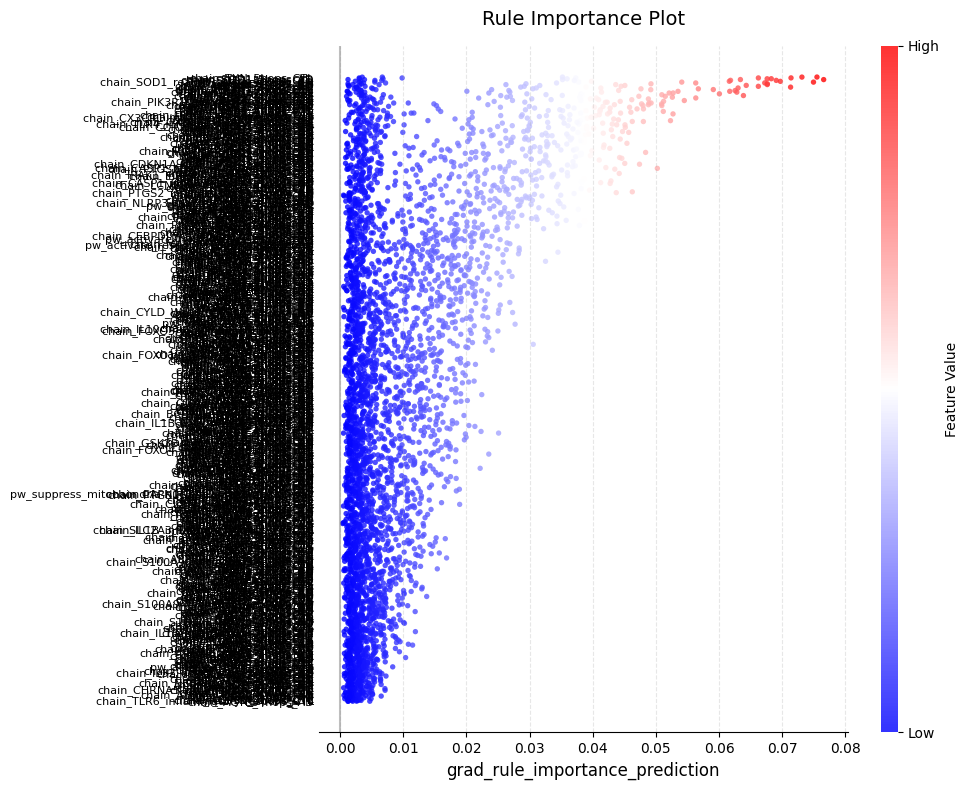

Top-5 rule_name by Permutation_importance(true_label):
['chain_MME_3hops_CTL', 'chain_PIK3R1_3hops_AD', 'chain_MME_APP_CTL', 'chain_MME_5hops_AD', 'chain_TLR4_5hops_AD']


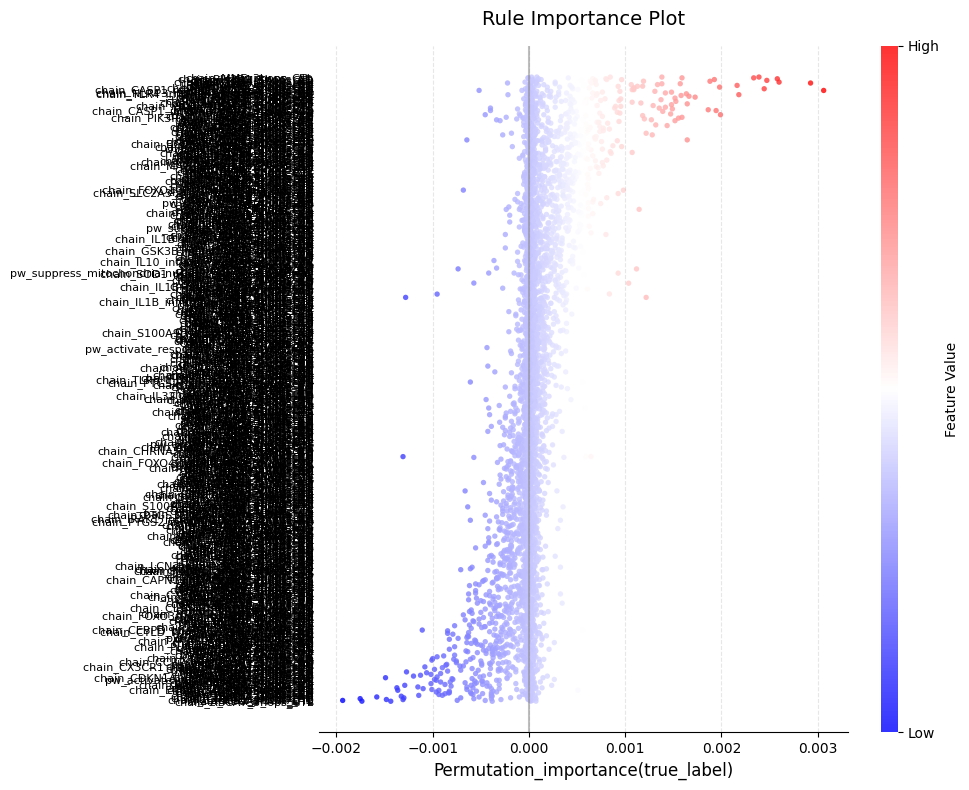

Top-5 rule_name by Permutation_importance(pred_label):
['chain_SOD1_5hops_CTL', 'chain_SOD1_5hops_AD', 'chain_TXN_5hops_CTL', 'chain_SOD1_3hops_AD', 'chain_SOD1_reactive oxygen spec_AD']


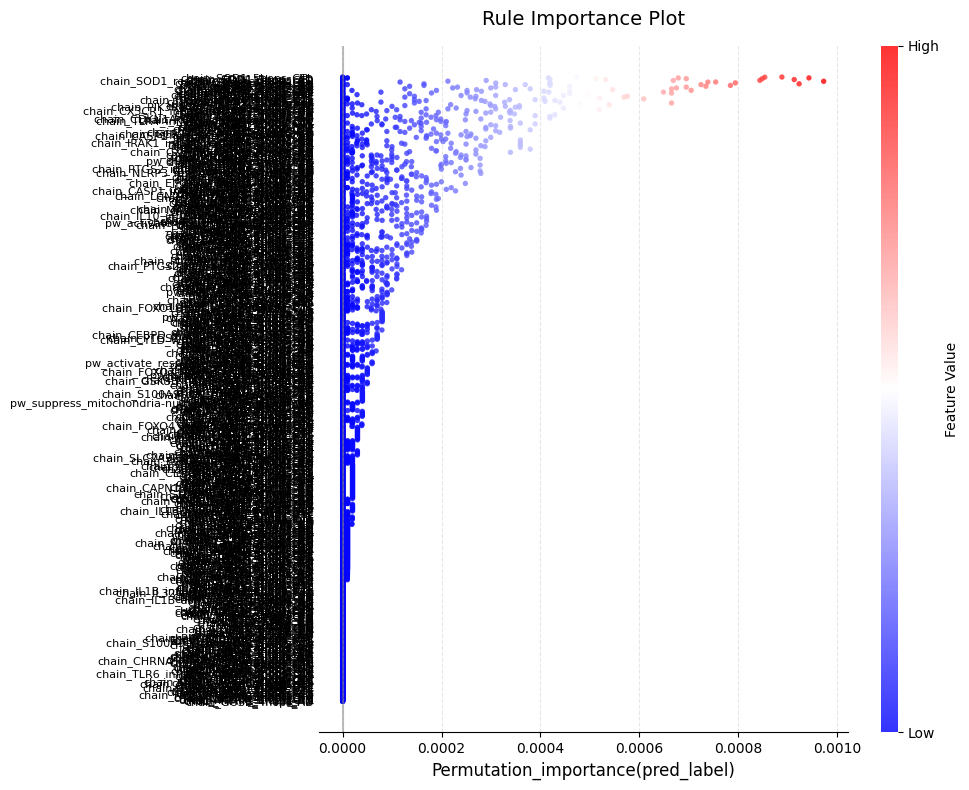

Top-5 rule_name by Integrated_Gradient_importance(true_label):
['chain_SOD1_5hops_AD', 'chain_TXN_5hops_CTL', 'chain_SOD1_3hops_AD', 'chain_SOD1_5hops_CTL', 'chain_SOD1_4hops_CTL']


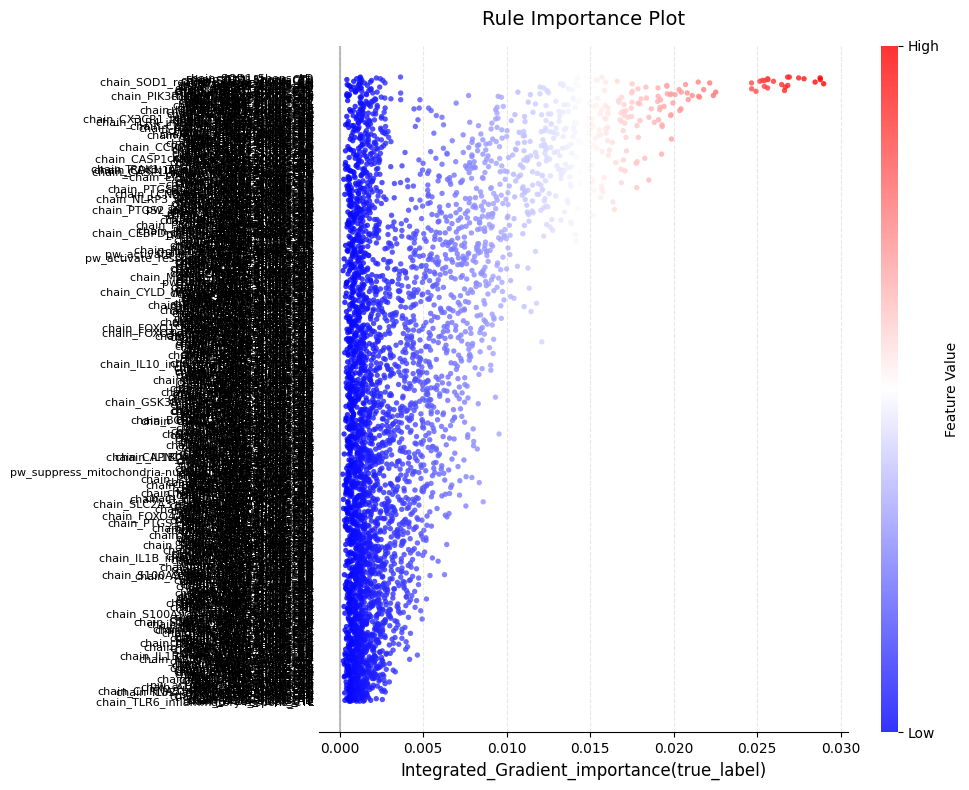

Top-5 rule_name by Integrated_Gradient_importance(pred_label):
['chain_TXN_5hops_CTL', 'chain_SOD1_5hops_AD', 'chain_SOD1_5hops_CTL', 'chain_SOD1_3hops_AD', 'chain_SOD1_4hops_CTL']


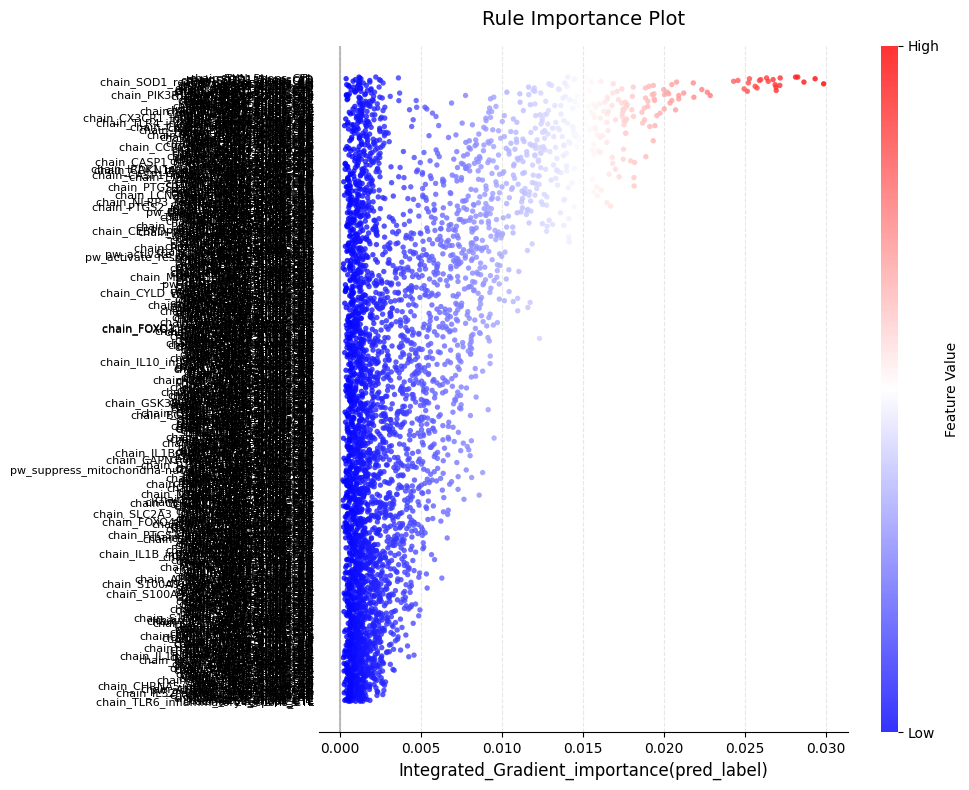

In [97]:
backbone = 'GAT'
dataset = 'ANMerge'
k = 4
model_type = "FuzzyGAT_topo_all_rules"
plot_df = df_rules[(df_rules['dataset']==dataset) &
                   (df_rules['k']==str(k)) &
                   (df_rules['model']==model_type)]

importance_types = ['grad_rule_importance_prediction',
                                'Permutation_importance(true_label)',
                                'Permutation_importance(pred_label)',
                                'Integrated_Gradient_importance(true_label)',
                                'Integrated_Gradient_importance(pred_label)']
for rip in importance_types:
    x_col = rip
    y_col = 'rule_name'

    _ = plot_rule_importance(df=plot_df, 
                                        x_col=x_col, 
                                        y_col=y_col, 
                                        title="Rule Importance Plot",
                                        cmap='bwr',
                                        central_vertical_line=0.0,
                                        interpolate=False)

## Per-sample Rule Contribution Analysis
+ df_samples contains rule contributions for each sample of each rule;
+ generated from Integrated Gradient;
+ gate shows how much the GNN part and Rule part contribute to model calssification

In [70]:
df_samples

,degrees,clustering,eigenvector_centrality,degree_centrality,avg_edge_weight,gate,Label,Prediction,fold,model,...,chain_GPS1_5hops_AD,chain_GUSB_4hops_AD,chain_GUSB_5hops_CTL,chain_GUSB_5hops_AD,chain_PPP1CA_4hops_AD,chain_PPP1CA_5hops_CTL,chain_PPP1CA_5hops_AD,dataset,k,backbone
0,-0.000098,-0.007199,0.003123,-0.000210,0.000521,0.508388,1,1,1,FuzzyGAT_topo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ANMerge,4,GAT
1,0.000030,-0.006596,-0.002288,-0.000160,0.000390,0.484337,1,1,1,FuzzyGAT_topo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ANMerge,4,GAT
2,-0.000094,0.027169,-0.000740,0.000041,-0.000007,0.458731,0,1,1,FuzzyGAT_topo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ANMerge,4,GAT
3,-0.000108,-0.007754,-0.000457,-0.000160,0.000168,0.500154,0,1,1,FuzzyGAT_topo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ANMerge,4,GAT
4,0.000111,-0.026526,-0.066061,0.000503,-0.003861,0.476903,0,0,1,FuzzyGAT_topo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ANMerge,4,GAT
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69095,-0.001858,0.003231,-0.000704,0.000743,0.000020,0.702342,1,1,5,FuzzyGIN_topo_all_rules,...,0.002879,0.001547,0.002417,-0.001478,-0.000923,-0.000168,-0.000324,ANMerge,4,GIN
69096,0.000887,0.002136,-0.000830,-0.000252,-0.000003,0.712895,1,1,5,FuzzyGIN_topo_all_rules,...,0.001162,0.000988,0.001966,-0.001192,-0.001491,0.000144,-0.000661,ANMerge,4,GIN
69097,-0.000961,0.000815,-0.000448,0.000550,0.000018,0.657470,1,1,5,FuzzyGIN_topo_all_rules,...,-0.001832,-0.001389,-0.002235,0.001510,0.001049,0.000559,0.000326,ANMerge,4,GIN
69098,-0.002036,-0.000265,0.000769,-0.001826,-0.000159,0.676286,1,0,5,FuzzyGIN_topo_all_rules,...,-0.000536,-0.000438,0.000773,-0.001326,0.000792,-0.000058,0.000886,ANMerge,4,GIN


In [101]:
df_samples.columns
non_rule_columns = ['sample_id','Label', 'Prediction','gate','fold', 'model', 'dataset', 'k',
       'backbone']
rule_columns = [col for col in df_samples.columns if col not in non_rule_columns]
cols = non_rule_columns + rule_columns

df_samples = df_samples[cols]
df_samples

,sample_id,Label,Prediction,gate,fold,model,dataset,k,backbone,degrees,...,chain_ACTB_5hops_AD,chain_GPS1_4hops_AD,chain_GPS1_5hops_CTL,chain_GPS1_5hops_AD,chain_GUSB_4hops_AD,chain_GUSB_5hops_CTL,chain_GUSB_5hops_AD,chain_PPP1CA_4hops_AD,chain_PPP1CA_5hops_CTL,chain_PPP1CA_5hops_AD
0,DCR00001_1,1,1,0.508388,1,FuzzyGAT_topo,ANMerge,4,GAT,-0.000098,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,DCR00004_1,1,1,0.484337,1,FuzzyGAT_topo,ANMerge,4,GAT,0.000030,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,DCR00009_1,0,1,0.458731,1,FuzzyGAT_topo,ANMerge,4,GAT,-0.000094,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,DCR00013_1,0,1,0.500154,1,FuzzyGAT_topo,ANMerge,4,GAT,-0.000108,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,DCR00014_1,0,0,0.476903,1,FuzzyGAT_topo,ANMerge,4,GAT,0.000111,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69095,TLSMCI607_1,1,1,0.702342,5,FuzzyGIN_topo_all_rules,ANMerge,4,GIN,-0.001858,...,0.001489,0.003278,0.001061,0.002879,0.001547,0.002417,-0.001478,-0.000923,-0.000168,-0.000324
69096,TLSMCI608_1,1,1,0.712895,5,FuzzyGIN_topo_all_rules,ANMerge,4,GIN,0.000887,...,0.002209,0.001674,0.000589,0.001162,0.000988,0.001966,-0.001192,-0.001491,0.000144,-0.000661
69097,TLSMCI609_1,1,1,0.657470,5,FuzzyGIN_topo_all_rules,ANMerge,4,GIN,-0.000961,...,-0.002652,-0.002672,-0.000680,-0.001832,-0.001389,-0.002235,0.001510,0.001049,0.000559,0.000326
69098,TLSMCI611_1,1,0,0.676286,5,FuzzyGIN_topo_all_rules,ANMerge,4,GIN,-0.002036,...,0.000389,0.000244,0.000341,-0.000536,-0.000438,0.000773,-0.001326,0.000792,-0.000058,0.000886


Top-5 rule_name by DCR00001_1
: ['chain_HDAC2_H3F3A_CTL', 'chain_PIK3R1_5hops_AD', 'chain_HDAC2_5hops_AD', 'chain_PIK3R1_4hops_AD', 'chain_SOD1_5hops_AD']


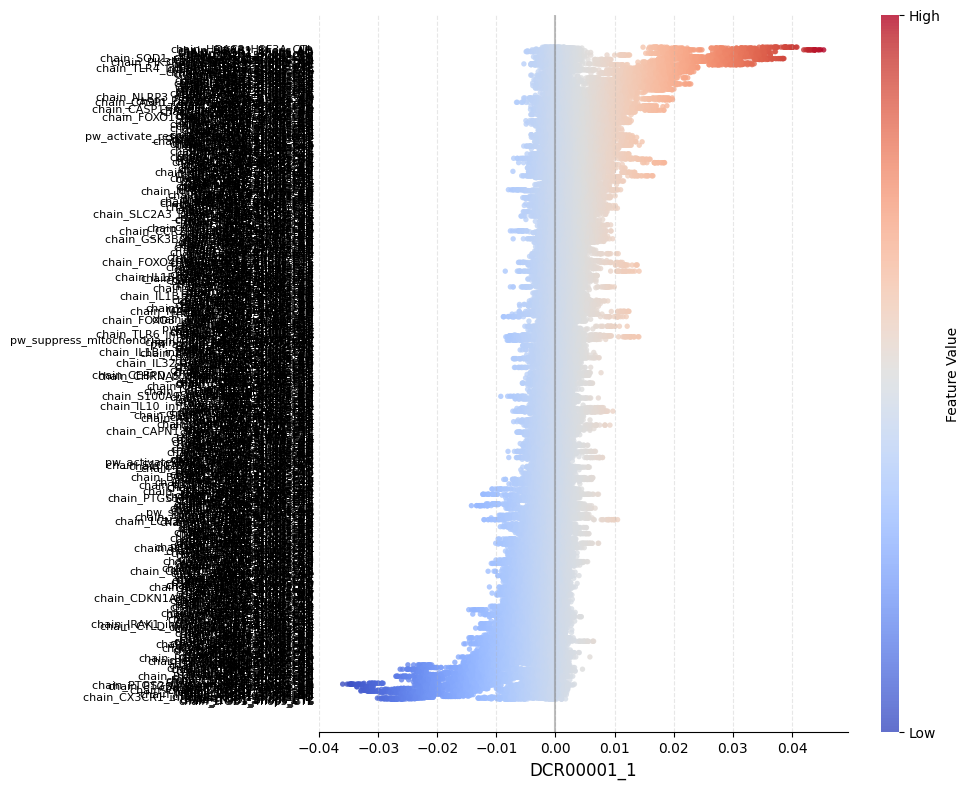

Top-5 rule_name by DCR00001_1
: ['chain_HDAC2_H3F3A_CTL', 'chain_PIK3R1_5hops_AD', 'chain_HDAC2_5hops_AD', 'chain_SOD1_5hops_AD', 'chain_PIK3R1_4hops_AD']


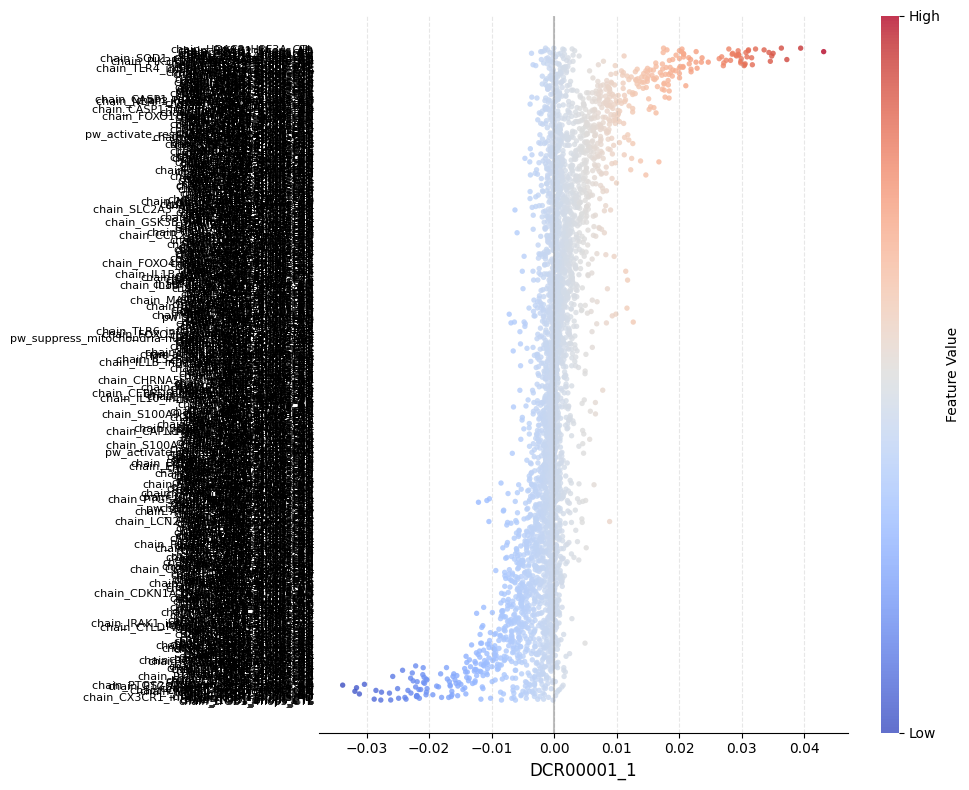

In [ ]:
non_rule_cols = ['gate', 'Label', 'Prediction', 'fold', 'model','dataset', 'k',
       'backbone']
backbone = 'GAT'
dataset = 'ANMerge'
k = 4
model_type = "FuzzyGAT_topo_all_rules"
per_sample_rule_attribution(df_samples=df_samples, dataset=dataset, k= k, model_type=model_type,
                            x_col='DCR00001_1',interpolate=True)

per_sample_rule_attribution(df_samples=df_samples, dataset=dataset, k= k, model_type=model_type,
                            x_col='DCR00001_1',interpolate=False)

Top-5 rule_name by DCR00001_1
: ['chain_SOD1_reactive oxygen spec_AD', 'chain_HDAC2_memory_AD', 'chain_SOD1_APP_AD', 'chain_HDAC2_H3F3A_CTL', 'chain_PIK3R1_Insulin Resistance_AD']


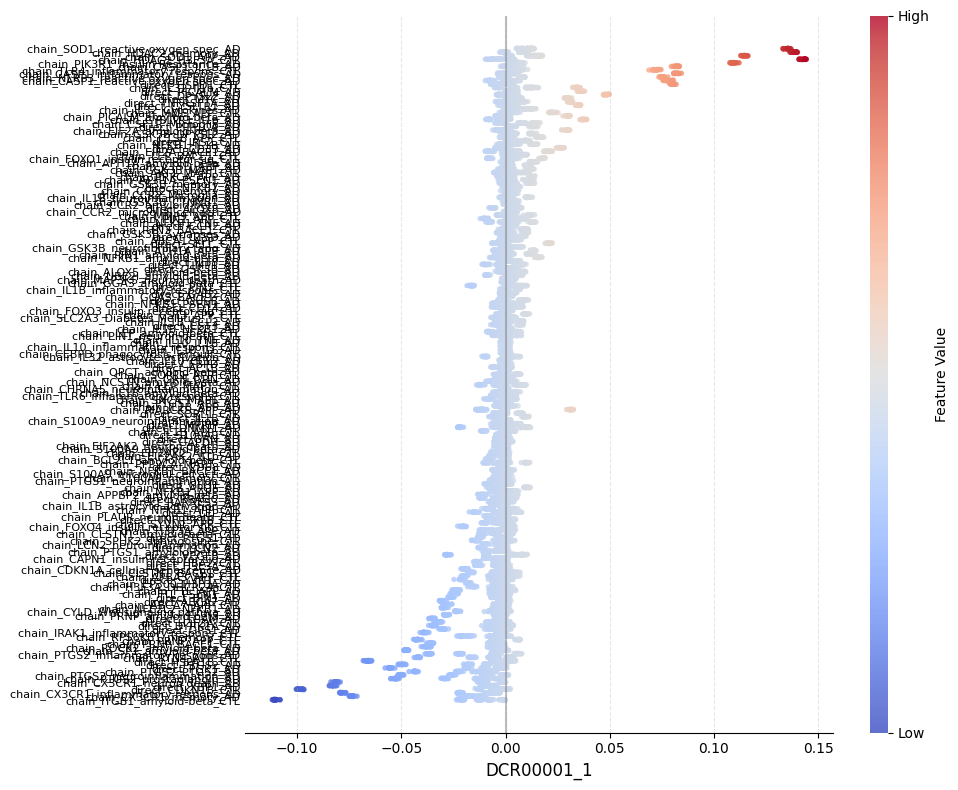

Top-5 rule_name by DCR00001_1
: ['chain_SOD1_reactive oxygen spec_AD', 'chain_HDAC2_memory_AD', 'chain_SOD1_APP_AD', 'chain_HDAC2_H3F3A_CTL', 'chain_PIK3R1_Insulin Resistance_AD']


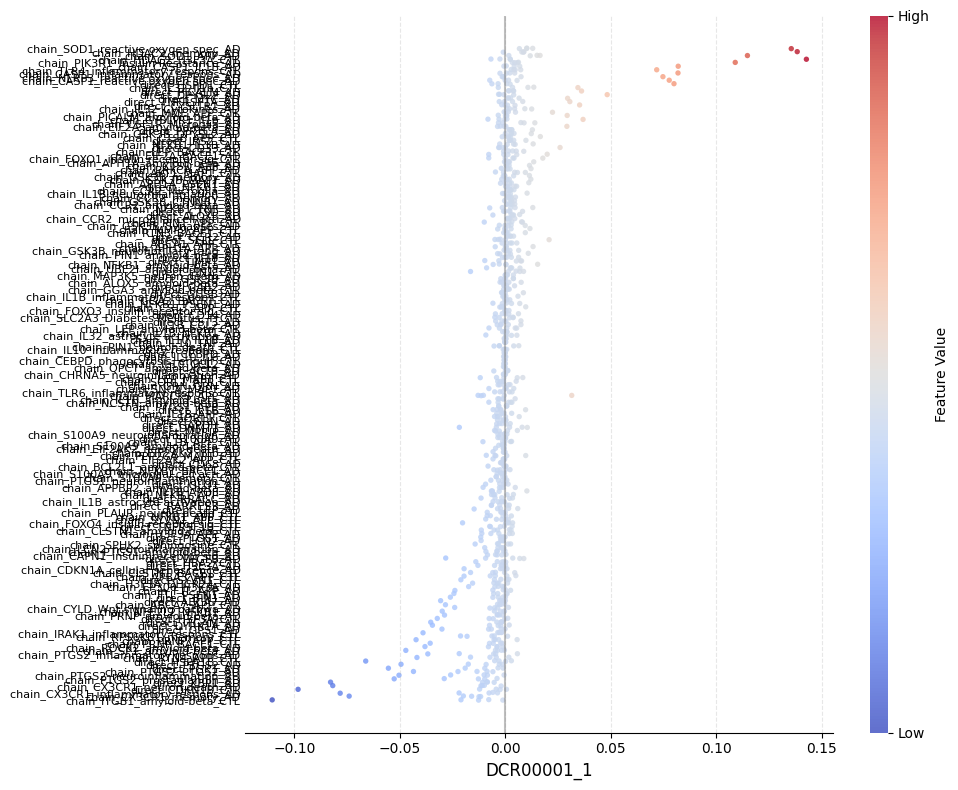

In [88]:
backbone = 'GAT'
dataset = 'ANMerge'
k = 4
model_type = "FuzzyGAT_direct_rules"
per_sample_rule_attribution(df_samples=df_samples, dataset=dataset, k= k, model_type=model_type,
                            x_col='DCR00001_1',interpolate=True)

per_sample_rule_attribution(df_samples=df_samples, dataset=dataset, k= k, model_type=model_type,
                            x_col='DCR00001_1',interpolate=False)